##**2.4 파이토치 코드 맛보기**



In [1]:
# [필요한 라이브러리 호출]
import torch
import torch .nn as nn
import numpy as np # 벡터 및 행렬 연산에서 매우 편리한 기능을 제공하는 파이썬 라이브러리 패키지
import pandas as pd # 데이터 처리를 위해 널리 사용되는 파이썬 라이브러리 패키지
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
# [데이터 호출]
cols = ['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety', 'output']
dataset = pd.read_csv('/content/car.data', names=cols)
display(dataset.head())

,price,maint,doors,persons,lug_capacity,safety,output
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


- 인덱스는 0부터 시작
- 다섯 개의 행이 단어와 숫자로 구성
- 단어를 벡터로 바꾸어 주는 임베딩 처리가 필요함

<Axes: ylabel='count'>

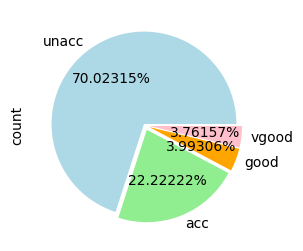

In [3]:
# [예제 데이터셋 분포]
fig_size = plt.rcParams["figure.figsize"]
fig_size[0] = 8
fig_size[1] = 3
plt.rcParams["figure.figsize"] = fig_size
dataset.output.value_counts().plot(kind='pie' , autopct='%0.05f%%',
                                   colors=['lightblue', 'lightgreen', 'orange', 'pink' ], explode=(0.02, 0.05, 0.05, 0.05))

- 대부분의 자동차(70%)는 허용 불가능한 상태에 있음
- 20%만 허용 가능한 수준
- 즉, 양호한 상태의 자동차 비율이 매우 낮은 것을 볼 수 있음

<br>

예제 데이터 정보를 확인했으니 데이터에 대한 **전처리 단계**

▼

- 딥러닝은 통계 알고리즘을 기반으로 하기 때문에 단어를 숫자로 변환해야 함
- astype() 메서드를 이용하여 범주 특성을 갖는 데이터를 범주형 타입으로 변환
- 또한 파이토치를 이용한 모델 학습을 해야 하므로 범주형 타입을 텐서로 변환해야 함

(참고로 이번 예제에서 사용하는 데이터는 모두 범주형 데이터)

In [4]:
# [데이터를 범주형 타입으로 변환]
categorical_columns = ['price', 'maint', 'doors', 'persons','lug_capacity', 'safety'] # 예제 데이터셋 칼럼들의 목록

for category in categorical_columns:
  dataset[category] = dataset[category].astype('category') # astype() 메서드를 이용하여 데이터를 범주형으로 변환

price = dataset['price'].cat.codes.values
maint = dataset['maint'].cat.codes.values
doors = dataset['doors'].cat.codes.values
persons = dataset['persons'].cat.codes.values
lug_capacity = dataset['lug_capacity'].cat.codes.values
safety = dataset['safety'].cat.codes.values

categorical_data = np.stack([price, maint, doors , persons, lug_capacity, safety], 1)
categorical_data[:10]

array([[3, 3, 0, 0, 2, 1],
       [3, 3, 0, 0, 2, 2],
       [3, 3, 0, 0, 2, 0],
       [3, 3, 0, 0, 1, 1],
       [3, 3, 0, 0, 1, 2],
       [3, 3, 0, 0, 1, 0],
       [3, 3, 0, 0, 0, 1],
       [3, 3, 0, 0, 0, 2],
       [3, 3, 0, 0, 0, 0],
       [3, 3, 0, 1, 2, 1]], dtype=int8)

- 범주형 데이터를 텐서로 변환하기 위해서는

> 범주형 데이터 ▶︎ dataset[category] ▶︎ 넘파이 배열 ▶︎ 텐서

즉, 파이토치로 모델을 학습시키기 위해서는 텐서 형태로 변환해야 하는데, 넘파이 배열을 통해 텐서를 생성할 수 있음

- 범주형 데이터를 숫자로 변환하기 위해 cat.codes를 사용
- cat.codes는 어떤 클래스가 어떤 숫자로 매핑되어 있는지 확인이 어려운 단점이 있으므로 주의해서 사용해야 함
- np.stack은 두 개 이상의 넘파이 객체를 합칠 때 사용
- np.stack은 배열들을 새로운 축으로 합쳐줌. 따라서 반드시 두 배열의 차원이 동일해야 함
- np.concatenate도 넘파이 객체를 합칠 때 사용하는 메서드
- np.concatenate는 선택한 축을 기준으로 두 개의 배열을 연결


In [5]:
# [배열을 텐서로 변환]
categorical_data = torch.tensor(categorical_data, dtype=torch.int64)
categorical_data[:10]

tensor([[3, 3, 0, 0, 2, 1],
        [3, 3, 0, 0, 2, 2],
        [3, 3, 0, 0, 2, 0],
        [3, 3, 0, 0, 1, 1],
        [3, 3, 0, 0, 1, 2],
        [3, 3, 0, 0, 1, 0],
        [3, 3, 0, 0, 0, 1],
        [3, 3, 0, 0, 0, 2],
        [3, 3, 0, 0, 0, 0],
        [3, 3, 0, 1, 2, 1]])

In [6]:
# [레이블로 사용할 칼럼을 텐서로 변환]
outputs = pd.get_dummies(dataset.output)
outputs = outputs.values
outputs = torch. tensor(outputs).flatten() # 1차원 텐서로 변환

print(categorical_data.shape)
print (outputs.shape)

torch.Size([1728, 6])
torch.Size([6912])


- get_dummies는 가변수로 만들어 주는 함수 (문자를 숫자 (0,1)로 바꾸어 준다는 의미)

- ravel(), reshape(), flatten()은 텐서의 차원을 바꿀 때 사용

- 워드 임베딩은 유사한 단어끼리 유사하게 인코딩되도록 표현하는 방법
- 또한, 높은 차원의 임베딩일수록 단어 간의 세부적인 관계를 잘 파악할 수 있음
- 따라서 단일 숫자로 변환된 넘파이 배열을 N차원으로 변경하여 사용


In [7]:
# [범주형 칼럼을 N차원으로 변환]
categorical_column_sizes = [len(dataset[column].cat.categories) for column in
                            categorical_columns]
categorical_embedding_sizes = [(col_size, min(50, (col_size+1)//2)) for col_size in
                               categorical_column_sizes]
print(categorical_embedding_sizes)

[(4, 2), (4, 2), (4, 2), (3, 2), (3, 2), (3, 2)]


In [8]:
# [데이터셋 분리]
total_records = 1728
test_records = int (total_records * .2) # 전체 데이터 중 20%를 테스트 용도로 사용
categorical_train_data = categorical_data[:total_records - test_records]
categorical_test_data = categorical_data[total_records - test_records:total_records]
train_outputs = outputs[:total_records - test_records]
test_outputs = outputs[total_records - test_records:total_records]

In [9]:
# [데이터셋 분리 확인]
print(len (categorical_train_data))
print(len(train_outputs))
print(len(categorical_test_data))
print(len(test_outputs))

1383
1383
345
345


In [10]:
# 모델의 네트워크 생성
class Model(nn.Module):
  def __init__(self, embedding_size, output_size, layers, p=0.4):
    super().__init__()
    self.all_embeddings = nn.ModuleList([nn.Embedding(ni, nf) for ni,
                                          nf in embedding_size])
    self.embedding_dropout = nn.Dropout(p)

    all_layers = []
    num_categorical_cols = sum((nf for ni, nf in embedding_size))
    input_size = num_categorical_cols # 입력층의 크기를 찾기 위해 범주형 칼럼 개수를 input_size 변수에 저장

    for i in layers:
      all_layers.append (nn.Linear(input_size, i))
      all_layers.append(nn.ReLU(inplace=True ))
      all_layers.append (nn.BatchNorm1d(i))
      all_layers.append (nn.Dropout(p))
      input_size = i

    all_layers.append(nn.Linear(layers[-1], output_size))
    self.layers = nn. Sequential (*all_layers) # 신경망의 모든 계층이 순차적으로 실행되도록 모든 계층에 대한 목록(all_layers)을 nn.Sequential 클래스로 전달

  def forward (self, x_categorical):
    embeddings = []
    for i,e in enumerate(self.all_embeddings):
      embeddings.append(e(x_categorical[:,i]))

    x = torch.cat(embeddings, 1) # 넘파이의 concatenate와 같지만 대상이 텐서가 됩니다.
    x = self.embedding_dropout(x)
    x = self.layers(x)
    return x

- 클래스 형태로 구현되는 모델은 nn.Module을 상속받음
- __init__()은 모델에서 사용될 파라미터와 신경망을 초기화하기 위한 용도로 사용하며, 객체가 생성될 때 자동으로 호출됨

> def __init__(self, embedding_size, output_size, layers, p=0.4)

- self: 첫 번째 파라미터는 self를 지정해야 하며 자기 자신을 의미

- embedding_size: 범주형 칼럼의 임베딩 크기
- output_size: 출력층의 크기
- layers: 모든 계층에 대한 목록
- p: 드롭아웃 (기본값은 0.5)

---

- super().__init__()은 부모 클래스(nn.Module)에 접근할 때 사용
- 모델의 네트워크 계층을 구축하기 위해 for 문을 이용하여 각 계층을 all.layers 목록에 추가

[추가된 계층]
- Linear: 선형 계층은 입력 데이터에 선형 변환을 진행한 결과
> y = Wx + b

(y: 선형 계층의 출력 값 W: 가중치 x: 입력 값 b: 바이러스)

- ReLU: 배치 정규화 용도로 사용
- BatchNorm1d: 배치 정규화 용도로 사용
- Dropout: 과적합 방지에 사용

---

- forward() 함수는 학습 데이터를 입력받아 연산을 진행. 모델 객체를 데이터와 함께 호출하면 자동으로 실행됨

In [11]:
# [Model 클래스의 객체 생성]
model = Model(categorical_embedding_sizes, 4, [200, 100, 50] , p=0.4)
print(model)

Model(
  (all_embeddings): ModuleList(
    (0-2): 3 x Embedding(4, 2)
    (3-5): 3 x Embedding(3, 2)
  )
  (embedding_dropout): Dropout(p=0.4, inplace=False)
  (layers): Sequential(
    (0): Linear(in_features=12, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=50, bias=True)
    (9): ReLU(inplace=True)
    (10): BatchNorm1d(50, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): Dropout(p=0.4, inplace=False)
    (12): Linear(in_features=50, out_features=4, bias=True)
  )
)


- 모델 훈련 전에 손실 함수와 옵티마이저에 대해 정의해야 함
- 크로스 엔트로피 손실 함수를 사용
- 또한, 옵티마이저로는 아담을 사용

In [12]:
# 모델의 파라미터 정의
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters() , lr=0.001)

- 파이토치는 GPU에 최적화된 딥러닝 프레임워크이기에, GPU가 없다면 CPU를 사용할 수 있도록 지정해 주어야 함

In [13]:
# [CPU/GPU 사용 지정]
if torch.cuda.is_available():
  device = torch.device('cuda') # GPU가 있다면 GPU를 사용
else:
  device = torch.device('cpu') # GPU가 없다면 CPU를 사용

In [14]:
# [모델 학습]
epochs = 500
aggregated_losses = []
train_outputs = train_outputs.to(device=device, dtype=torch.int64)

for i in range (epochs):
  i += 1
  y_pred = model(categorical_train_data).to(device)
  single_loss = loss_function(y_pred, train_outputs)
  aggregated_losses.append(single_loss)

  if i%25 == 1:
    print(f'epoch: {i:3} loss: {single_loss.item() :10.8f}')

  optimizer.zero_grad()
  single_loss.backward()
  optimizer.step()

print(f'epoch: {i:3} loss: {single_loss.item() :10.10f}')

epoch:   1 loss: 1.63549411
epoch:  26 loss: 1.45589066
epoch:  51 loss: 1.36716974
epoch:  76 loss: 1.25116622
epoch: 101 loss: 1.10857546
epoch: 126 loss: 0.95425797
epoch: 151 loss: 0.85784096
epoch: 176 loss: 0.77977031
epoch: 201 loss: 0.69671088
epoch: 226 loss: 0.66444528
epoch: 251 loss: 0.63978726
epoch: 276 loss: 0.62073189
epoch: 301 loss: 0.60748017
epoch: 326 loss: 0.59815353
epoch: 351 loss: 0.60111833
epoch: 376 loss: 0.58909893
epoch: 401 loss: 0.59260005
epoch: 426 loss: 0.57858312
epoch: 451 loss: 0.56972569
epoch: 476 loss: 0.56279284
epoch: 500 loss: 0.5639243126


In [15]:
# [테스트 데이터셋으로 모델 예측]
test_outputs = test_outputs.to(device=device, dtype=torch.int64)
with torch.no_grad():
  y_val = model(categorical_test_data)
  loss = loss_function(y_val, test_outputs)
print(f'Loss: {loss:.8f}')

Loss: 0.56126767


- 코드를 실행하면 테스트 용도의 데이터셋에 대한 손실 값을 보여줌
- 이 값은 훈련 데이터셋에서 도출된 손실 값과 비슷하므로 과적합은 발생하지 않았다고 판단할 수 있음

In [16]:
# [모델의 예측 확인]
print(y_val[:5])

tensor([[ 2.9949,  1.5783, -3.8373, -3.8047],
        [ 2.3152,  1.2716, -3.2925, -3.5337],
        [ 4.3705,  2.3050, -5.4214, -5.7659],
        [ 2.6568,  1.2269, -2.9989, -3.5310],
        [ 3.0652,  2.2416, -6.2311, -6.8204]])


- 실제 출력이 0이면 인덱스 0의 값의 인덱스 1의 값보다 높아야 함

In [17]:
# [가장 큰 값을 갖는 인덱스 확인]
y_val = np.argmax(y_val, axis=1)
print(y_val[:5])

tensor([0, 0, 0, 0, 0])


- 출력 결과 모두 인덱스 0이 출력됨
- 즉, 인덱스가 0인 값이 인덱스가 1인 값보다 크므로 처리된 출력이 0임을 확인할 수 있음

In [18]:
# [테스트 데이터셋을 이용한 정확도 확인]
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
print(confusion_matrix(test_outputs,y_val))
print(classification_report(test_outputs, y_val))
print(accuracy_score(test_outputs, y_val))

[[253   6]
 [ 81   5]]
              precision    recall  f1-score   support

           0       0.76      0.98      0.85       259
           1       0.45      0.06      0.10        86

    accuracy                           0.75       345
   macro avg       0.61      0.52      0.48       345
weighted avg       0.68      0.75      0.67       345

0.7478260869565218


- 성능 평가 지표로 '정확도, 재현율, 정밀도, F1-스코어'가 있음

[정확도에 필요한 용어들]
- True Positive: 모델이 1이라고 예측했는데 실제 값도 1
- True Negative: 모델이 0이라고 예측했는데 실제 값도 0
- False Positive: 모델이 1이라고 예측했는데 실제 값은 0 --> Type 1 오류
- False Negative: 모델이 0이라고 예측했는데 실제 값은 1 --> Type 2 오류

<br>

**정확도**

: 전체 예측 건수에서 정답을 맞힌 건수의 비율
- 정답이 긍정이든 부정이든 상관 없음

**재현율**

: 실제로 정답이 1이라고 할 때 모델도 1로 예측한 비율

**정밀도**

: 모델이 1이라고 예측한 것 중에서 실제로 정답이 1인 비율

**F1-스코어**

: 정밀도와 재현율의 조화 평균을 이용한 것이 F1-스코어 평가

- 일반적으로 정밀도와 재현율은 트레이드오프 관계로 정밀도가 높으면 재현율이 낮고, 재현율이 높으면 정밀도가 낮음.

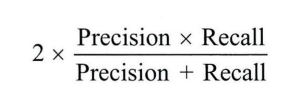